# Домашнее задание №3. Линейная регрессия. Расширение признакового пространства. Регуляризация. Валидация

## Ф.И.О: Чайкин Владимир Денисович

### Описание.

Домашнее задание состоит из 2-х частей:
  - теоретическая часть
  - практическая часть
    - реализация модуля линейной регрессии
    -  эксперименты

**На проверку требуется отправить zip архив, который будет содержать следующие файлы:**
  - модуль ``modules`` с реализованными классами
  - заполненный блокнот в формате ``.ipynb``
  - заполненный блокнот в формате ``.html`` **(в jupyter: File -> Save and Export Notebook As -> HTML -> ...)**

-------------------------

## Теоретическая часть. (4 points)

**№1.** (2 point) Найдите субдифференциалы для следующих функций:
- $f(x) = \max(0, 1 − ax), \ \ a \ — \ const$,  во всех точках

- $f(x) = \sin x, \ x \in [0; \frac{3}{2} \pi]$


$f(x) = \max(0, 1 - ax)$

Функция является выпуклой. Рассмотрим 3 случая нахождения $a$ относительно 0

**1: $a > 0$**

- При $x < \frac{1}{a}$: $f(x) = 1 - ax$, производная $f'(x) = -a$
  $$\partial f(x) = \{-a\}$$

- При $x > \frac{1}{a}$: $f(x) = 0$, производная $f'(x) = 0$
  $$\partial f(x) = \{0\}$$

- При $x = \frac{1}{a}$: точка излома
  Левая производная: $-a$, правая производная: $0$
  $$\partial f\left(\frac{1}{a}\right) = [-a, 0]$$

**2: $a < 0$**

- При $x > \frac{1}{a}$: $f(x) = 1 - ax$, $f'(x) = -a$ ($-a > 0$)
  $$\partial f(x) = \{-a\}$$

- При $x < \frac{1}{a}$: $f(x) = 0$, $f'(x) = 0$
  $$\partial f(x) = \{0\}$$

- При $x = \frac{1}{a}$: точка излома
  Левая производная: $0$, правая производная: $-a$
  $$\partial f\left(\frac{1}{a}\right) = [0, -a]$$

**3: $a = 0$**

$f(x) = \max(0, 1) = 1$
$$\partial f(x) = \{0\} \quad \forall x$$

### Итого:

$$
\partial f(x) =
\begin{cases}
\{-a\}, & a > 0, x < \frac{1}{a} \\
\{0\}, & a > 0, x > \frac{1}{a} \\
[-a, 0], & a > 0, x = \frac{1}{a} \\
\{-a\}, & a < 0, x > \frac{1}{a} \\
\{0\}, & a < 0, x < \frac{1}{a} \\
[0, -a], & a < 0, x = \frac{1}{a} \\
\{0\}, & a = 0
\end{cases}
$$

$f(x) = \sin x$ на $[0, \frac{3\pi}{2}]$


Синус на этом интервале не является выпуклым

- $[0, \pi]$: $\sin x$ —  вогнута
- $[\pi, \frac{3\pi}{2}]$: $\sin x$ —  выпукла

По определению требуется выполнение неравенства для всех $x \in \mathbb{R}$.

**В точке $x = \frac{3\pi}{2}$:**
- Это точка глобального минимума $\sin x$ на $\mathbb{R}$
- Для $z = 0$ выполняется: $\sin x \geq -1 + 0 \cdot (x - \frac{3\pi}{2}) = -1$
- Неравенство верно для всех $x \in \mathbb{R}$
$$\partial f\left(\frac{3\pi}{2}\right) = \{0\}$$

$$
\partial f(x) =
\begin{cases}
\varnothing, & x \in [0, \frac{3\pi}{2}) \\
\{0\}, & x = \frac{3\pi}{2}
\end{cases}
$$

Если считать, что мы работаем *только* на отрезке, то можно определить субградиенты выпуклой части:

$$∂f(x) = {cos(x)}$$


**№2.** (2 point) Рассмотрим задачу линейной регрессии с регуляризацией:

$$L(w) = \| Xw - y\|_2^2 + \lambda R(w)$$

И попробуем разобраться, в каких случаях возникает случай вырожденного (нулевого решения) для LASSO и Ridge регрессии.

- Покажите, что если оптимальное решение $w^*$ функционала $L(w) = \| Xw - y\|_2^2 + \lambda \|w\|_1$ равно нулю, то выполняется неравенство $\| 2 X^T y \|_{\infty} \le \lambda$.

Для выпуклой негладкой функции условие минимума:
$$
0 \in \partial L(w^*)
$$

Найдем субдифференциал в точке $w^* = 0$.
Разобьем функцию $$L = f + \lambda*g$$:
$$
\nabla f(w) = 2X^T(Xw - y)
$$
В точке $w^* = 0$:
$$
\nabla f(0) = -2X^Ty
$$
$$
\partial \|w\|_1 \bigg|_{w=0} = \{v \in \mathbb{R}^d : \|v\|_\infty \leq 1\}
$$

Условие оптимальности:
$$
0 \in -2X^Ty + \lambda \{v : \|v\|_\infty \leq 1\}
$$
Существует $v$ с $\|v\|_\infty \leq 1$ такая, что:
$$
0 = -2X^Ty + \lambda v
$$

А значит
$$
\|2X^Ty\|_\infty = \lambda \|v\|_\infty \leq \lambda
$$


- Покажите, что для функционала $L(w) = \| Xw - y\|_2^2 + \lambda \| w \|_2^2$ при $X^Ty \neq 0$ не существует $\lambda$ такого, что оптимальное решение $w^*$ обращается в нуль.

Условие минимума для гладкой функции:
$$
\nabla L(w^*) = 0
$$

$$
\nabla L(w) = 2X^T(Xw - y) + 2\lambda w
$$

В точке $w = 0$:
$$
\nabla L(0) = 2X^T(X\cdot 0 - y) + 2\lambda \cdot 0 = -2X^Ty
$$

Для оптимальности $w^* = 0$ необходимо:
$$
\nabla L(0) = 0 \quad \Rightarrow \quad -2X^Ty = 0 \quad \Rightarrow \quad X^Ty = 0
$$

Но по условию $X^Ty \neq 0$, следовательно:
$$
\nabla L(0) \neq 0
$$

------------------------

## Практическая часть. (16 points)

Данная часть задания направлена на ознакомление с линейными моделями и градиентными методами обучения. В задании необходимо:
1. Написать на языке Python собственную реализацию модели линейной регрессии с произвольной функцией потерь и реализацию функции и градиента функции потерь для линейной регрессии. Реализации можно частично проверить через юнит-тесты (запускаются командой ``pytest tests.py``).
2. Провести описанные ниже эксперименты с модельными данными и приложенным датасетом.
3. Написать отчёт о проделанной работе (в формате jupyter notebook).

### Реализация алгоритмов. (3 points)

Везде под выборкой объектов будем понимать ``numpy.ndarray`` размера $N \times D$ или разреженную матрицу ``scipy.sparse.csr_matrix`` того же размера, под ответами для объектов выборки будем понимать ``numpy.ndarray`` размера $N$ , где $N$ — количество объектов в выборке, $D$ — размер признакового пространства. Подразумевается, что первый столбец выборки объектов соответствует признаку для смещения и равен единице.

- **``losses.py``** (1 point)
  - класс в этом модуле задаёт конкретную функцию потерь, которую можно использовать для обучения линейной модели. Обратите внимание на то, что подсчёт всех функций может быть полностью векторизован (т.е. их можно реализовать без циклов). Предложенная в задании функция потерь должна поддерживать использование $l2$-регуляризации. Обратите внимание, что признак для смещения **не** должен учитываться в регуляризаторе.
  - Класс должен поддерживать как плотные матрицы (``numpy.ndarray``), так и разреженные матрицы (``scipy.sparse.csr_matrix``). Класс ``LinearLoss`` наследуется от абстрактного класса BaseLoss и реализует два метода: ``func`` и ``grad``.
    - ``func(self, X, y, w)`` — вычисление значения функции потерь на матрице признаков $X$, векторе ответов $y$ с вектором весов $w$.
    - ``grad(self, X, y, w)`` — вычисление значения градиента функции потерь на матрице признаков $X$, векторе ответов $y$ с вектором весов $w$.
  - У обоих методов одинаковые аргументы:
     - $X$ - выборка объектов
     - $y$ - вектор ответов
     - $w$ - вектор коэффициентов модели ``numpy.ndarray``.

В данном задании предлагается реализовать следующую функцию потерь:

$$L(X,y,w, \lambda) = \frac{1}{N} \| Xw - y \|_2^2 + \lambda \|w\|_2^2$$

- **``linear_model.py``** (2 points)
  - модуль с реализацией линейной модели, поддерживающей обучение через полный и стохастический градиентные спуски. Линейная модель должна задаваться в классе LinearModel. Параметр $\eta_k > 0$ — темп обучения (learning rate) для градиентного спуска, где $k$ — номер эпохи, должен параметризовываться формулой: $\eta_k = \dfrac{\alpha}{k^{\beta}}, \ где \ \ \alpha, \beta \ — \ \ заданные \ константы, \ \ k \ — \ \ номер \ итерации$

  - Описание методов класса:
    - ``__init__`` — конструктор (инициализатор) класса с параметрами:
      - ``loss_function`` — функция потерь, заданная классом, наследованным от ``BaseLoss``
      - ``batch_size`` — размер подвыборки, по которой считается градиент, если ``None``, то необходимо использовать полный градиент
      - ``step_alpha`` — параметр выбора шага градиентного спуска
      - ``step_beta`` — параметр выбора шага градиентного спуска
      - ``tolerance`` — точность, по достижении которой, необходимо прекратить оптимизацию.
        - **В данном случае в качестве критерия останова требуется реализовать вариант:** $\| w_{current} - w_{previous} \| \le tolerance$
      - ``max_iter`` — максимальное число итераций
    - ``fit(self, X, y, w_0=None, trace=False)`` — обучение линейной модели:
      - ``X`` - выборка объектов
      - ``y`` - вектор ответов
      - ``w_0`` - начальное приближение вектора весов, если ``None``, то необходимо инициализировать внутри метода
      - ``trace`` - индикатор, нужно ли возвращать информацию об обучении
        - Если ``trace is True``, то метод должен вернуть словарь ``history``, содержащий информацию о поведении метода оптимизации во время обучения. Длина словаря ``history`` — количество эпох. Элементы словаря в случае полного градиентного спуска:
          - ``history[’time’]`` — содержит время, потраченное на обучение каждой эпохи
          - ``history[’func’]`` — содержит значения функционала на обучающей выборке на каждой эпохе
          - ``history[’func_val’]`` — содержит значения функционала на валидационной выборке на каждой эпохе
        - Обратите внимание, что ``trace is True`` сильно замедляет обучение методов, т.к. требует в конце эпохи подсчитывать значение функции. Не используйте его ни в каких экспериментах, кроме экспериментов, где необходимо исследовать поведение функции в зависимости от гиперпараметров.
        - Нет необходимости проводить честное семплирование для каждого батча в методе стохастического градиентного спуска. Вместо этого предлагается в начале одной эпохи сгенерировать случайную перестановку индексов объектов, а затем последовательно выбирать объекты для нового батча из элементов этой перестановки.
    - ``predict(self, X)`` — получение предсказаний модели
      - ``X`` - выборка объектов
      - $\rightarrow$ Метод должен вернуть ``numpy.ndarray`` такого же размера, как и первая размерность матрицы ``X``.
    - ``get_objective(self, X, y)`` — вычисление значения функции потерь
      - ``X`` - выборка объектов
      - ``y`` - вектор ответов
      - $\rightarrow$ Функция должна вернуть вещественное число.
    - ``get_weights(self)`` — получить вектор линейных коэффициентов модели

--------------------------

### Эксперименты. (13 points)

Данные для этого задания находятся в файле ``hw3_data.csv``. Данные состоят из двух колонок: ``text`` и ``y``. Текст представляет собой комментарии пользователей. А целевая переменная, колонка ``y``, отражает степень токсичности комментария, которую вам необходимо будет предсказать.

**1.** (2 points)

*1.1* Произведите предварительную обработку текста. Приведите все тексты к нижнему регистру. Замените в тексте все символы, не являющиеся буквами и цифрами, на пробелы. Примените алгоритм [лемматизации](https://ru.wikipedia.org/wiki/%D0%9B%D0%B5%D0%BC%D0%BC%D0%B0%D1%82%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F) (например, [WordNetLemmatizer](https://www.nltk.org/api/nltk.stem.WordNetLemmatizer.html?highlight=wordnet) из библиотеки [nltk](https://www.nltk.org/index.html)) к коллекции. Удалите из текста стоп-слова (например, используя список стоп-слов из nltk).

Замечание. Полезные функции: ``str.lower``, ``str.split``, ``str.isalnum``, ``re.sub``, ``re.split``.

In [2]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

df = pd.read_csv("hw3_data.csv")

import ssl
try:
    _create_unverified_https_context = ssl._create_unverified_context
    ssl._create_default_https_context = _create_unverified_https_context
except Exception:
    pass

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9]", " ", text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(token) for token in tokens if token not in stop_words]
    return " ".join(tokens)

df["clean_text"] = df["text"].astype(str).apply(preprocess_text)

df.head()


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


,text,y,clean_text
0,oh why dear johnny boy part one again do you w...,2.076477,oh dear johnny boy part one want fucking fight...
1,savant13 is a fat shite,3.580757,savant13 fat shite
2,i am english i am i do not want to get blocked...,0.805528,english want get blocked fu k
3,and why the fuck should i care g e t r i d o f...,4.582293,fuck care g e r f l l p l e e j ck
4,yo dear sir james paul you a fruity ass nigga ...,2.077456,yo dear sir james paul fruity as nigga get lif...


*1.2.* Разделите данные на обучение, валидацию и тест. Для теста выберете $30\%$ __случайных__ объектов из датасета. Оставшиеся данные разбейте в соотношении $70/30$ (обучение/валидация). Рекомендуется использовать функцию ``sklearn.model_selection.train_test_split`` c параметром ``random_state=42``.

In [3]:
from sklearn.model_selection import train_test_split

train_val_df, test_df = train_test_split(
    df,
    test_size=0.3,
    random_state=42,
    shuffle=True
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.3,
    random_state=42,
    shuffle=True
)

print("Размер train:", train_df.shape)
print("Размер val:", val_df.shape)
print("Размер test:", test_df.shape)


Размер train: (23515, 3)
Размер val: (10078, 3)
Размер test: (14398, 3)


*1.3.* Преобразуйте текст в разреженную матрицу ``scipy.sparse.csr_matrix``, где значение $x$ в позиции $(i, j)$ сответствует [$tf-idf$](https://ru.wikipedia.org/wiki/TF-IDF) характеристке $j$-го слова в $i$-ом документе. Рекомендуется использовать конструктор [``sklearn.feature_extraction.text.TfidfVectorizer``](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html). Добавьте в данные единичный столбец на нулевой позиции.

Замечание 1. У ``TfidfVectorizer`` есть несколько методов для работы, используйте ``fit_transform`` и ``fit`` для обучающей выборки, используйте ``transform`` для тестовой.

Замечание 2. Используйте параметр ``min_df``, чтобы уменьшить размерность данных и ускорить проведение экспериментов. Рекомендуется использовать ``min_df`` не меньше 5.

Замечание 3. Для добавления единичного столбца, можно воспользоваться следующей инструкцией: ``from scipy.sparse import hstack, csr_matrix
X = csr_matrix(hstack([csr_matrix(np.ones((X.shape[0], 1))), X]))``

In [4]:
import numpy as np
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer

X_train_texts = train_df["clean_text"].tolist()
X_val_texts   = val_df["clean_text"].tolist()
X_test_texts  = test_df["clean_text"].tolist()

vectorizer = TfidfVectorizer(min_df=5)

X_train = vectorizer.fit_transform(X_train_texts)

X_val   = vectorizer.transform(X_val_texts)
X_test  = vectorizer.transform(X_test_texts)

X_train = csr_matrix(hstack([csr_matrix(np.ones((X_train.shape[0], 1))), X_train]))
X_val   = csr_matrix(hstack([csr_matrix(np.ones((X_val.shape[0], 1))), X_val]))
X_test  = csr_matrix(hstack([csr_matrix(np.ones((X_test.shape[0], 1))), X_test]))

y_train = train_df["y"].values
y_val   = val_df["y"].values
y_test  = test_df["y"].values

**2.** (3 points) В спецификации предлагается использовать следующую формулу для выбора темпа обучения $\gamma_k$:

$$\gamma_k = \dfrac{\alpha}{k^{\beta}}, \ где \ \ \alpha, \beta \ — \ заданные \ константы, \ \ k \ — \ номер \ итерации$$

   - Исследуйте поведение градиентного спуска для задачи линейной регрессии в зависимости от следующих параметров:
        - параметр темпа обучения ``step_alpha``
        - параметр темпа обучения ``step_beta``

   - Исследование поведения подразумевает анализ следующих зависимостей на обучающей и валидационной выборках:
        - зависимость значения функции потерь от реального времени работы метода
        - зависимость значения функции потерь от эпохи метода
        - значение метрики качества после обучения метода

В качестве метрики качества здесь и далее предлагается использовать **MAE**.

***Дисклеймер:*** *это исследовательская часть задания, где вы сами решаете, как много экспериментов проводить, как ограничить пространство поиска и прочие параметры. Оценка качества экспериментов будет основана на субъективных ощущениях проверяющего. Таким образом моделируется реальное исследование, когда вы в большинстве случаев не можете оценить, в какой области находится достаточно хорошее решение и сколько потребуется экспериментов для его достижения.*

=== alpha=0.1, beta=0.0 ===


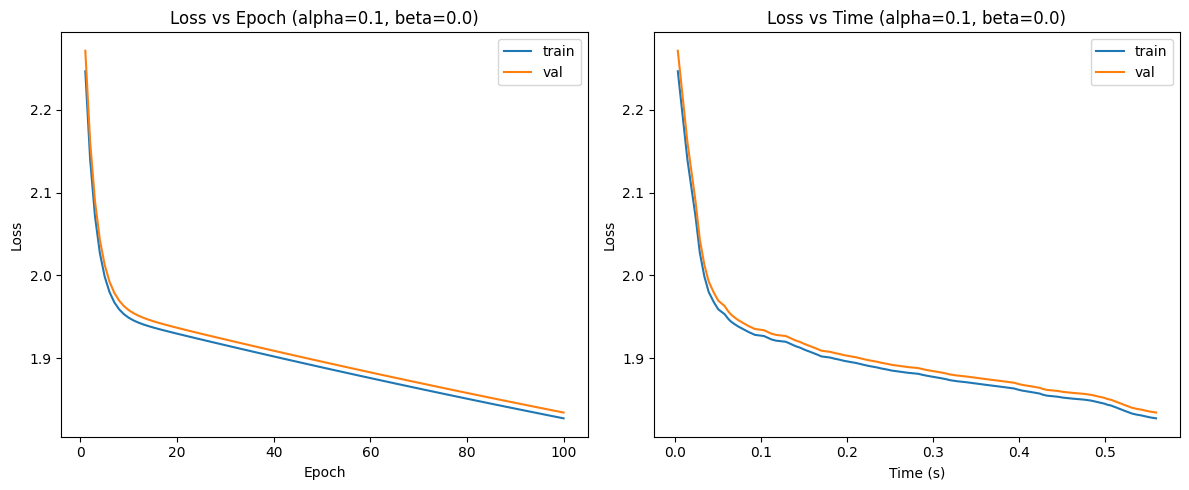

Validation MAE: 1.0211
Final train loss: 1.8273
Final val loss: 1.8343
Total training time: 1.26s

=== alpha=0.1, beta=0.5 ===


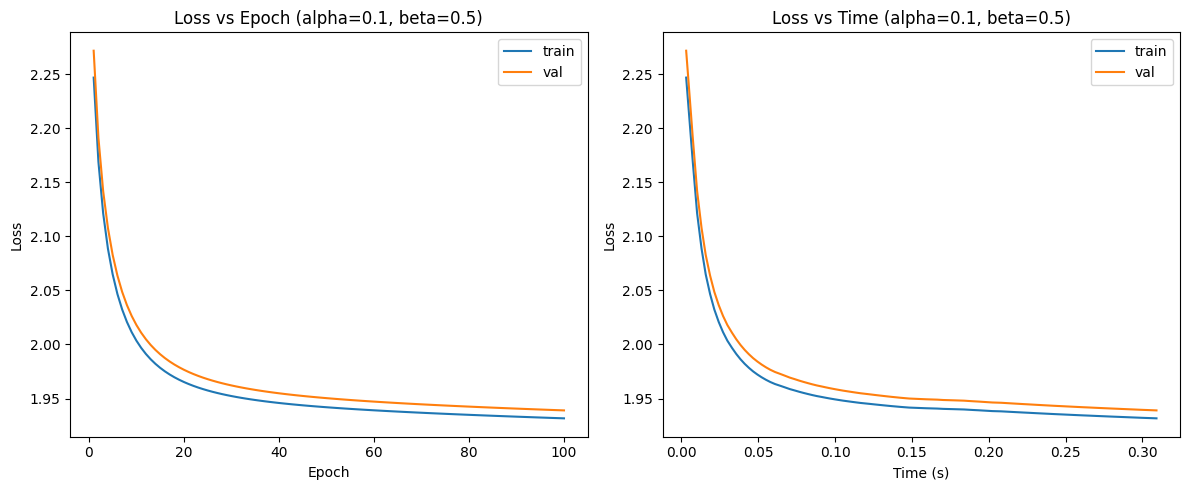

Validation MAE: 1.0487
Final train loss: 1.9317
Final val loss: 1.9391
Total training time: 0.54s

=== alpha=0.1, beta=1.0 ===


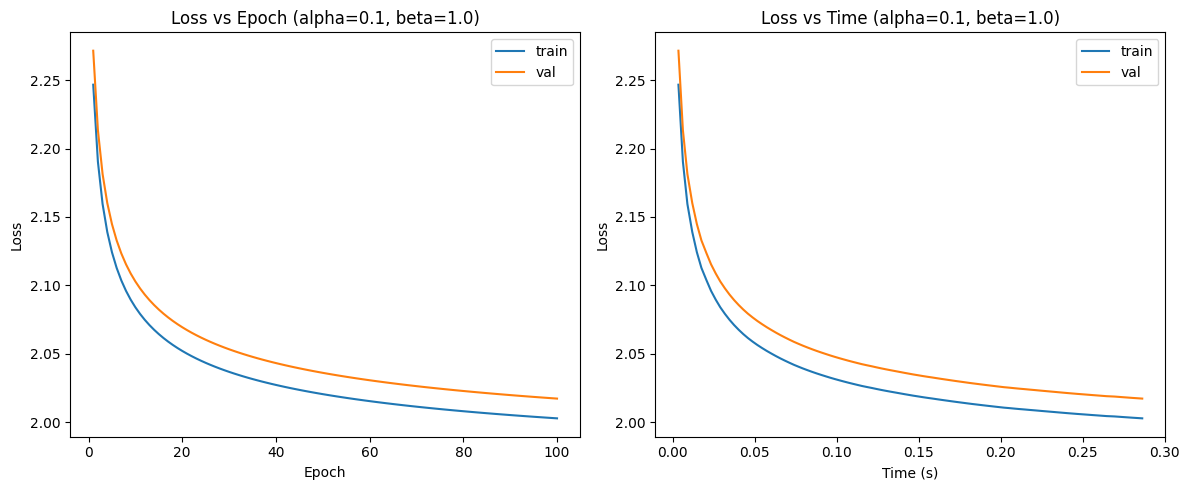

Validation MAE: 1.0591
Final train loss: 2.0028
Final val loss: 2.0172
Total training time: 0.50s

=== alpha=0.5, beta=0.0 ===


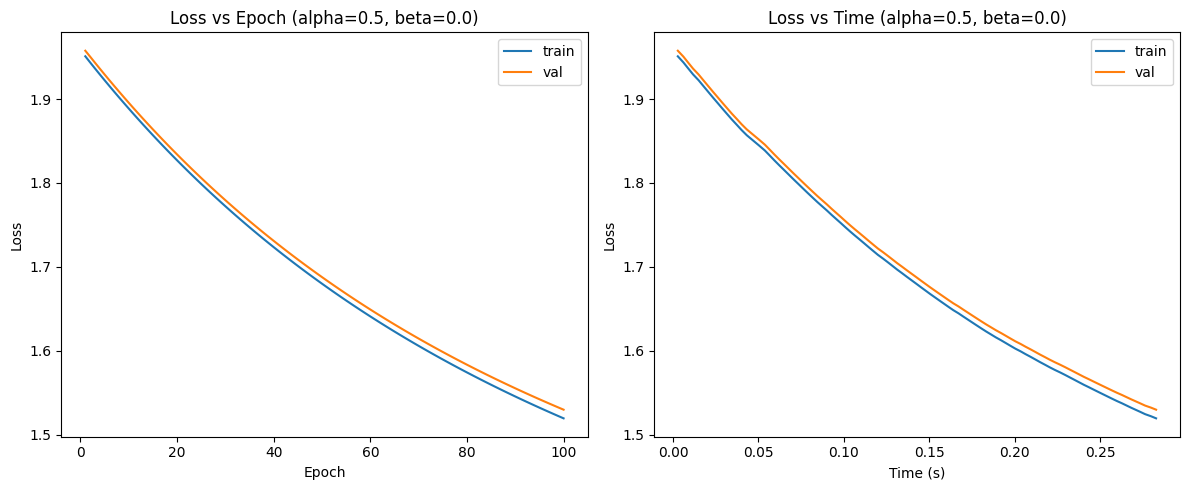

Validation MAE: 0.9343
Final train loss: 1.5193
Final val loss: 1.5297
Total training time: 0.49s

=== alpha=0.5, beta=0.5 ===


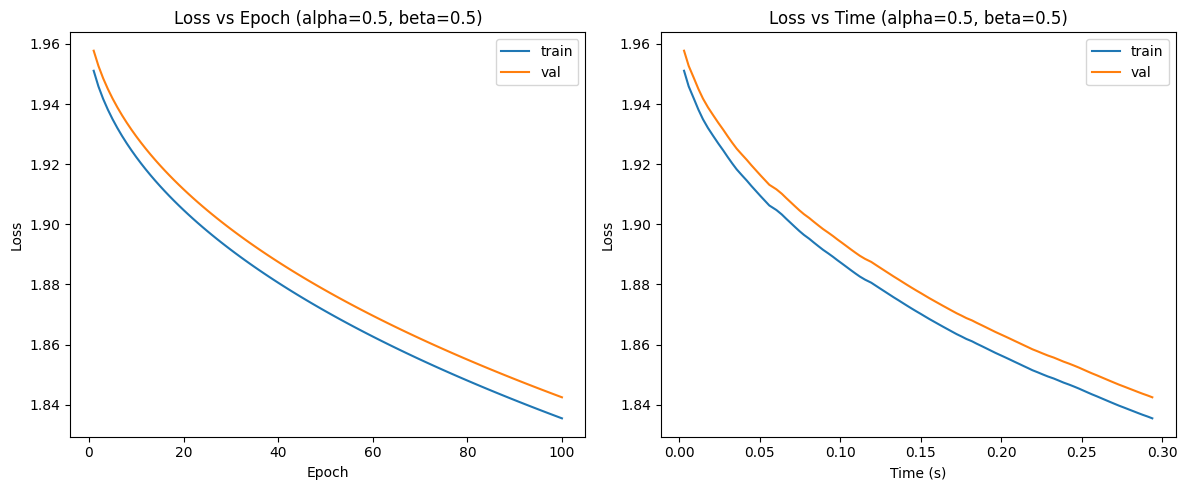

Validation MAE: 1.0234
Final train loss: 1.8355
Final val loss: 1.8425
Total training time: 0.51s

=== alpha=0.5, beta=1.0 ===


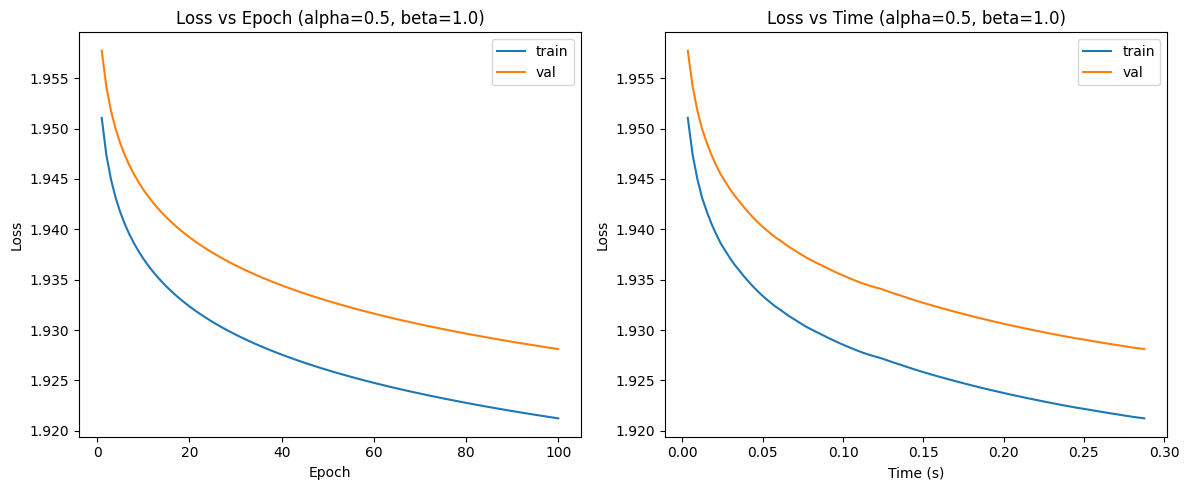

Validation MAE: 1.0467
Final train loss: 1.9212
Final val loss: 1.9281
Total training time: 0.50s

=== alpha=1.0, beta=0.0 ===


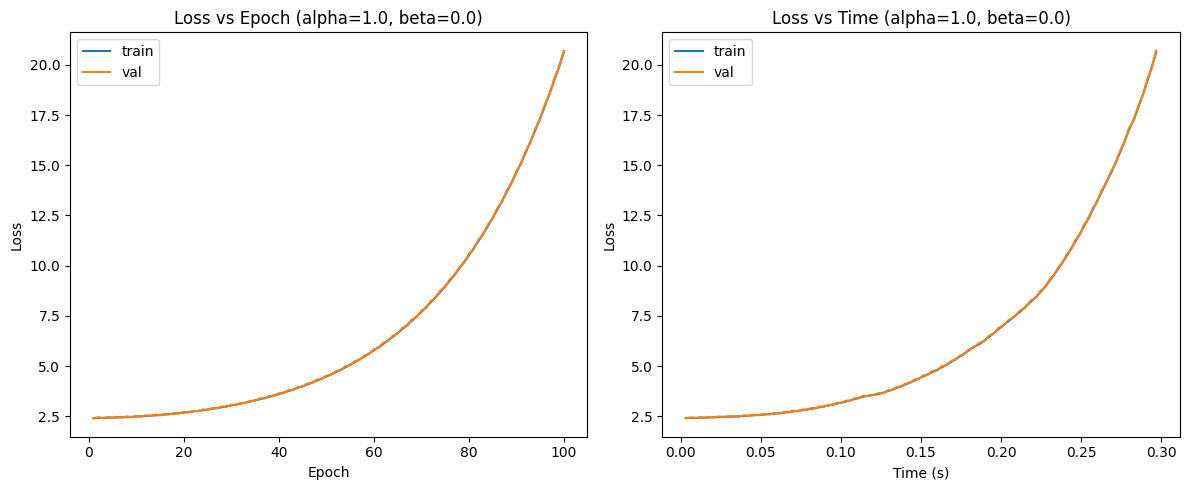

Validation MAE: 4.3972
Final train loss: 20.6110
Final val loss: 20.7006
Total training time: 0.52s

=== alpha=1.0, beta=0.5 ===


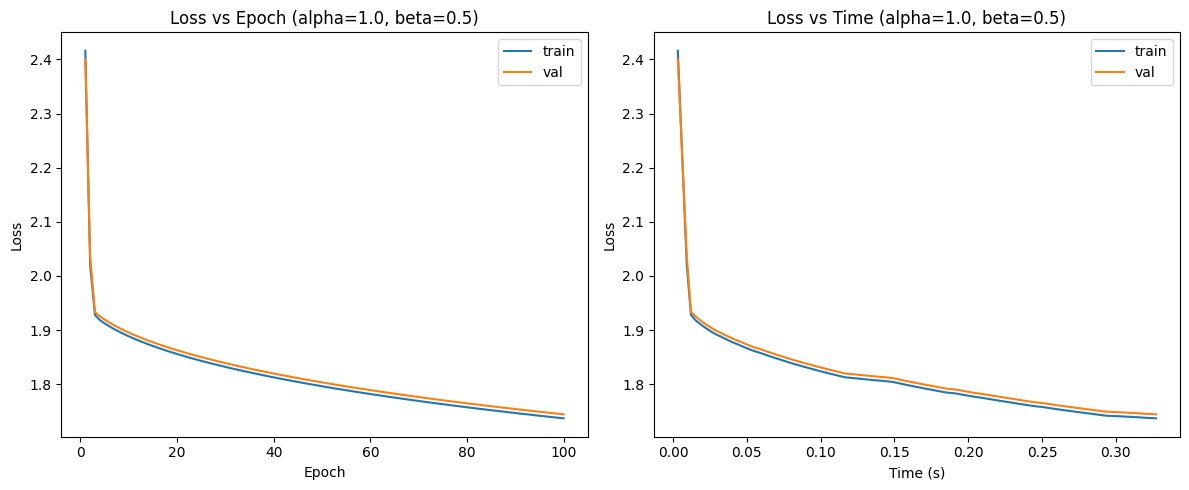

Validation MAE: 0.9960
Final train loss: 1.7369
Final val loss: 1.7443
Total training time: 0.57s

=== alpha=1.0, beta=1.0 ===


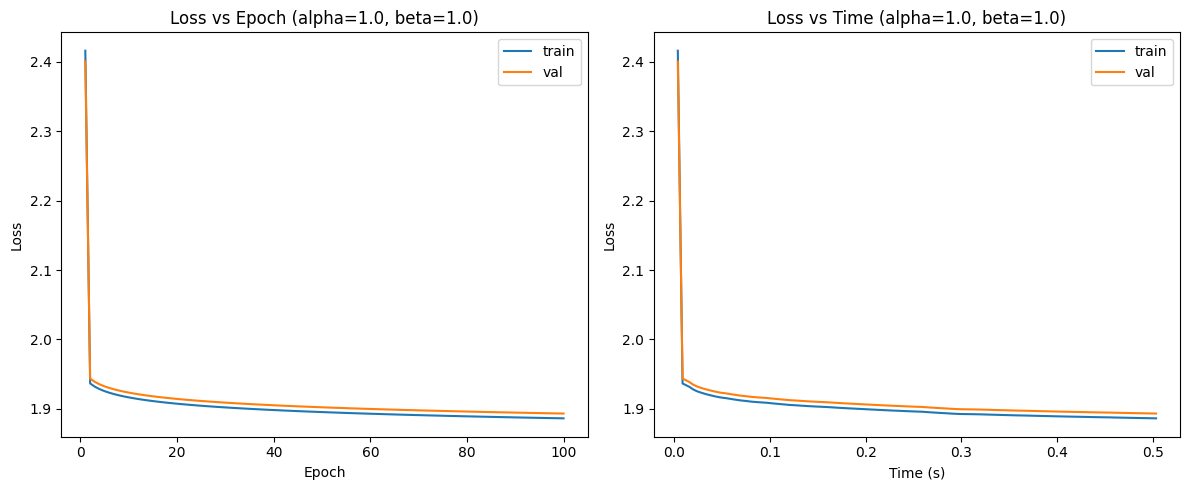

Validation MAE: 1.0373
Final train loss: 1.8863
Final val loss: 1.8932
Total training time: 1.18s

=== Сравнение результатов ===
alpha=0.1, beta=0.0: MAE=1.0211, Final train loss=1.8273
alpha=0.1, beta=0.5: MAE=1.0487, Final train loss=1.9317
alpha=0.1, beta=1.0: MAE=1.0591, Final train loss=2.0028
alpha=0.5, beta=0.0: MAE=0.9343, Final train loss=1.5193
alpha=0.5, beta=0.5: MAE=1.0234, Final train loss=1.8355
alpha=0.5, beta=1.0: MAE=1.0467, Final train loss=1.9212
alpha=1.0, beta=0.0: MAE=4.3972, Final train loss=20.6110
alpha=1.0, beta=0.5: MAE=0.9960, Final train loss=1.7369
alpha=1.0, beta=1.0: MAE=1.0373, Final train loss=1.8863

Лучшая комбинация: alpha=0.5, beta=0.0
Лучший MAE: 0.9343


In [9]:
import time
import matplotlib.pyplot as plt
from linear_model import LinearModel
from losses import LinearLoss
from sklearn.metrics import mean_absolute_error
import numpy as np

loss_fn = LinearLoss(l2_coef=0.0)

step_alpha_list = [0.1, 0.5, 1.0]
step_beta_list = [0.0, 0.5, 1.0]
max_iter = 100

results = []

for alpha in step_alpha_list:
    for beta in step_beta_list:
        print(f"=== alpha={alpha}, beta={beta} ===")

        model = LinearModel(
            loss_function=loss_fn,
            batch_size=None,
            step_alpha=alpha,
            step_beta=beta,
            tolerance=1e-8,
            max_iter=max_iter
        )

        start_time = time.time()
        history = model.fit(X_train, y_train, trace=True, X_val=X_val, y_val=y_val)
        total_time = time.time() - start_time

        y_pred_val = model.predict(X_val)
        mae_val = mean_absolute_error(y_val, y_pred_val)

        results.append({
            "alpha": alpha,
            "beta": beta,
            "loss_train": history['func'],
            "loss_val": history['func_val'],
            "times": history['time'],
            "mae_val": mae_val,
            "weights": model.get_weights()
        })

        plt.figure(figsize=(12,5))

        plt.subplot(1,2,1)
        epochs = range(1, len(history['func']) + 1)
        plt.plot(epochs, history['func'], label="train")
        if all(x is not None for x in history['func_val']):
            plt.plot(epochs, history['func_val'], label="val")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title(f"Loss vs Epoch (alpha={alpha}, beta={beta})")
        plt.legend()

        plt.subplot(1,2,2)
        cumulative_times = np.cumsum(history['time'])
        plt.plot(cumulative_times, history['func'], label="train")
        if all(x is not None for x in history['func_val']):
            plt.plot(cumulative_times, history['func_val'], label="val")
        plt.xlabel("Time (s)")
        plt.ylabel("Loss")
        plt.title(f"Loss vs Time (alpha={alpha}, beta={beta})")
        plt.legend()

        plt.tight_layout()
        plt.show()

        print(f"Validation MAE: {mae_val:.4f}")
        print(f"Final train loss: {history['func'][-1]:.4f}")
        if history['func_val'][-1] is not None:
            print(f"Final val loss: {history['func_val'][-1]:.4f}")
        print(f"Total training time: {total_time:.2f}s")
        print()

print("=== Сравнение результатов ===")
for result in results:
    print(f"alpha={result['alpha']}, beta={result['beta']}: "
          f"MAE={result['mae_val']:.4f}, "
          f"Final train loss={result['loss_train'][-1]:.4f}")

best_result = min(results, key=lambda x: x['mae_val'])
print(f"\nЛучшая комбинация: alpha={best_result['alpha']}, beta={best_result['beta']}")
print(f"Лучший MAE: {best_result['mae_val']:.4f}")

**5.** (3 points)
- Исследуйте поведение стохастического градиентного спуска для задачи линейной регрессии в зависимости от следующих параметров:
  - параметр темпа обучения ``step_alpha``
  - параметр темпа обучения ``step_beta``
  - размер подвыборки ``batch_size``

Замечание. Обратите внимание, что в стохастическом случае необходимо строить зависимости метрик качества от эпохи метода. За одну эпоху через оптимизацию модели проходит $N$ объектов, где $N$ — длина обучающей выборки. Если вы реализуете семплирование согласно спецификации задания, то за одну эпоху каждый объект пройдёт через оптимизацию ровно один раз. В полном градиентном спуске одна эпоха метода соответствует одной итерации обучения.

***Дисклеймер:*** *это исследовательская часть задания, где вы сами решаете, как много экспериментов проводить, как ограничить пространство поиска и прочие параметры. Оценка качества экспериментов будет основана на субъективных ощущениях проверяющего. Таким образом моделируется реальное исследование, когда вы в большинстве случаев не можете оценить, в какой области находится достаточно хорошее решение и сколько потребуется экспериментов для его достижения.*

Не успел дальше

**6.** (2 point) Сравните поведение двух методов между собой, сделайте выводы. Сравните оптимальные ``step_alpha`` и ``step_beta`` для разных методов.

**7.** (1 point) Подберите по отложенной выборке коэффициент $l2$-регуляризации модели.

**8.** (2 points) Выберите лучший алгоритм для тестовой выборки. Проанализируйте ошибки алгоритма. Проанализируйте и укажите общие черты объектов, на которых были допущены ошибки.